<a href="https://colab.research.google.com/github/Deltacp1/Deltacp1/blob/main/analise_salto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML

# as duas primeiras linhas são o cabeçalho: nome do marcador e eixo
dados = pd.read_csv('salto_exemplo.csv', header=[0,1])
dados.head()

CdM                       C7                     CLAV                   \
       X      Y         Z       X      Y         Z       X      Y         Z   
0  0.152  0.682  1059.970 -20.283 -0.226  1450.277  60.625 -0.122  1380.127   
1 -0.426  0.448  1059.635 -20.218 -0.333  1450.124  60.438  0.661  1380.448   
2  0.564 -0.360  1059.793 -19.149  0.217  1450.504  61.172  0.318  1380.137   
3  0.753 -0.751  1060.317 -19.552  0.126  1450.242  59.509 -0.595  1381.119   
4 -0.599 -1.482  1060.001 -19.729 -0.702  1450.609  60.244  0.081  1380.715   

    RASI  ...    RANK   LANK                     RTOE                  \
       X  ...       Z      X       Y       Z        X       Y       Z   
0 -0.744  ...  90.038 -0.155 -89.550  90.396  119.826  89.909  29.538   
1  0.637  ...  90.242  0.124 -89.971  90.063  120.606  90.535  29.368   
2 -0.465  ...  89.951 -0.432 -89.455  90.438  120.291  91.114  30.134   
3  0.681  ...  89.590 -0.411 -89.710  89.718  120.364  90.090  29.181   
4  0.026  ...  90.189  0.468 -90.030  90.443  120.308  89.997  29.509   

      LTOE                  
         X       Y       Z  
0  120.464 -89.472  29.339  
1  120.575 -89.502  30.695  
2  120.563 -89.786  29.826  
3  120.503 -89.531  29.964  
4  120.583 -89.564  30.142  

[5 rows x 33 columns]

In [3]:
nome_colunas = dados.columns.get_level_values(0).unique()
for i, marcador in enumerate(nome_colunas):
    print(marcador, ':', i)

CdM : 0
C7 : 1
CLAV : 2
RASI : 3
LASI : 4
RKNE : 5
LKNE : 6
RANK : 7
LANK : 8
RTOE : 9
LTOE : 10


In [4]:
coordenadas = dados.values.reshape(dados.shape[0], len(nome_colunas), 3)
print(coordenadas.shape)  # (500, 11, 3): amostras, marcadores, eixos

(500, 11, 3)


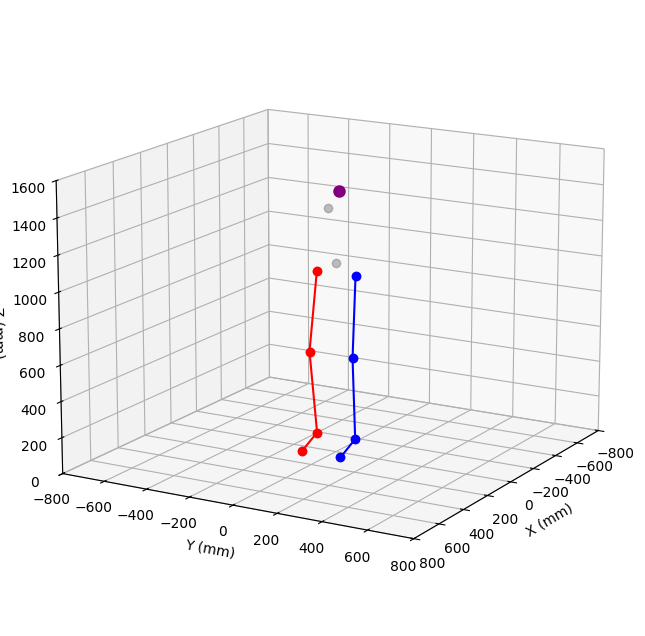

In [5]:
fig = plt.figure(figsize=(8,8), dpi=100)
ax = fig.add_subplot(projection='3d')   # equivale ao a3.Axes3D do capítulo
ax.view_init(elev=15, azim=30)

amostra = coordenadas[0]  # primeira amostra

# marcadores em cinza, sem linha
ax.plot3D(*amostra.T, lw=0, marker='o', color='grey', alpha=0.5)

# perna direita: RASI, RKNE, RANK, RTOE
ax.plot3D(*amostra[[3,5,7,9]].T, color='blue', marker='o')
# perna esquerda: LASI, LKNE, LANK, LTOE
ax.plot3D(*amostra[[4,6,8,10]].T, color='red', marker='o')
# C7 em roxo
ax.plot3D(*amostra[[1]].T, lw=0, marker='o', color='purple', markersize=8)

ax.set_xlim(-800, 800)
ax.set_ylim(-800, 800)
ax.set_zlim(0, 1600)   # mesmo alcance nos três eixos para não distorcer
ax.set_xlabel('X (mm)')
ax.set_ylabel('Y (mm)')
ax.set_zlabel('Z (mm)')
plt.show()

In [6]:
fig = plt.figure(figsize=(7,7), dpi=80)
ax = fig.add_subplot(projection='3d')
ax.view_init(elev=15, azim=30)
ax.set_xlim(-800, 800)
ax.set_ylim(-800, 800)
ax.set_zlim(0, 1600)
ax.set_xlabel('X (mm)')
ax.set_ylabel('Y (mm)')
ax.set_zlabel('Z (mm)')

pontos   = ax.plot3D(*coordenadas[0].T, lw=0, marker='o', color='grey', alpha=0.5)[0]
perna_d  = ax.plot3D(*coordenadas[0][[3,5,7,9]].T, color='blue', marker='o')[0]
perna_e  = ax.plot3D(*coordenadas[0][[4,6,8,10]].T, color='red', marker='o')[0]

def animate(quadro):
    pontos.set_data_3d(*coordenadas[quadro].T)
    perna_d.set_data_3d(*coordenadas[quadro][[3,5,7,9]].T)
    perna_e.set_data_3d(*coordenadas[quadro][[4,6,8,10]].T)
    return pontos, perna_d, perna_e

# intervalo de 10 ms, que corresponde a 100 Hz em tempo real
ani = animation.FuncAnimation(fig, animate, frames=len(coordenadas), interval=10, blit=False)
plt.close(fig)  # evita mostrar o gráfico estático duplicado
HTML(ani.to_jshtml())